#### AI in Production Management | Spring 2026 | Case Assignment
# Exercise 5: Direct Constrained Search for a 3-Feature PLC Rule

This notebook implements the stronger strategy for the industrial classifier:

1. Enumerate candidate **3-feature triplets**.
2. For each triplet, generate only PLC-allowed terms:
   - raw terms: `A`, `B`, `C`
   - products: `A * B`, `A * C`, `B * C`
   - ratios: `A / B`, `B / A`, etc.
3. Tune a small `DecisionTreeClassifier(max_depth <= 3)` with cross-validation.
4. Bias model selection toward avoiding the dangerous error: **actual BAD predicted GOOD**.
5. Extract the final rule as a clean PLC-compatible `IF / ELSE` block.

Unlike a separate feature-selection-first workflow, this searches the final deployable hypothesis space directly: the best 3 original features, the allowed arithmetic operator family, thresholds, logic, and tree settings are selected together.


## 0. Setup

This notebook is intentionally not pre-executed. Run it locally when you are ready. The exhaustive search is much heavier than the baseline notebook, but it is better aligned with the final PLC rule constraint.


In [1]:
# If your environment is missing dependencies, uncomment and run once:
# %pip install -q scikit-learn pandas numpy matplotlib seaborn joblib tqdm

from itertools import combinations
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.validation import check_is_fitted

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(iterable, **kwargs):
        return iterable

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 160)
pd.set_option("display.max_rows", 160)

RANDOM_STATE = 42
BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}


## 1. Configuration

The defaults use the engineered Exercise 3 master table. The key compute knobs are near the bottom of this cell.


In [ ]:
CANDIDATE_BASE_DIRS = [
    Path.cwd(),
    Path.cwd() / "Case",
    Path.cwd().parent,
]


def resolve_base_dir() -> Path:
    for candidate in CANDIDATE_BASE_DIRS:
        candidate = candidate.resolve()
        if (candidate / "outputs" / "exercise3_master_table_case_level.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find outputs/exercise3_master_table_case_level.csv. "
        "Start Jupyter from the project root or Case folder, or set DATA_PATH manually."
    )


BASE_DIR = resolve_base_dir()
DATA_PATH = BASE_DIR / "outputs" / "exercise3_master_table_case_level.csv"
PREDICTION_EXPORT_PATH = BASE_DIR / "outputs" / "exercise5_plc_predictions.csv"
TARGET_COLUMN = "Manual_Label"
LABEL_AVAILABLE_COLUMN = "label_available"
FEATURE_PREFIX = "feature_"

# Search objective. Higher is better. It heavily rewards catching BAD batches.
REFIT_METRIC = "safety_score"

# Cross-validation.
INNER_SPLITS = 5
OUTER_SPLITS = 5

# Direct constrained search space.
TERM_FAMILIES = [
    "raw",
    "raw_products",
    "raw_ratios",
    "raw_products_ratios",
]

# Keep None for the full exhaustive C(n_features, 3) triplet search.
# For a quick smoke test, set MAX_TRIPLETS = 20.
MAX_TRIPLETS = None

# Optional supervised screening before triplet enumeration.
# Keep None for the strict exhaustive search. Example: 15 reduces C(33,3) to C(15,3).
SCREEN_TOP_N_FEATURES = None

# Parallelism. Avoid nested parallel overload: outer triplet loop parallel, inner grid sequential.
TRIPLET_SEARCH_N_JOBS = -1
INNER_GRID_N_JOBS = 1
FIXED_CV_N_JOBS = -1

# Nested CV is the most honest generalization estimate but multiplies runtime.
RUN_NESTED_CV = False

# Final full-data search finds the deployable rule.
RUN_FINAL_SEARCH = True

print(f"Resolved base directory: {BASE_DIR}")
print(f"Dataset path: {DATA_PATH}")
print(f"Prediction export path: {PREDICTION_EXPORT_PATH}")


## 2. Load X/y

This section only loads the table and defines candidate columns. It does not perform target-aware selection. The search later performs model selection inside cross-validation.


,item,value
0,rows in raw table,2006
1,labeled rows used,1404
2,candidate feature count,33
3,BAD rows,682
4,GOOD rows,722
5,target column,Manual_Label


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33
1,41.0,778.0,21,105,21,0,6,0,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-48,0,4,4,112,-20.0,23
2,79.0,NaN,30,210,33,0,19,0,56,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,78,0,7,7,167,-91.0,43
7,60.0,NaN,23,150,23,0,6,0,20,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-58,0,6,6,102,-20.0,35
8,71.0,1260.0,30,164,26,0,6,0,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-37,0,4,4,112,-31.0,57
13,69.0,1042.0,23,163,30,0,13,0,35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,30,0,4,4,139,-71.0,41


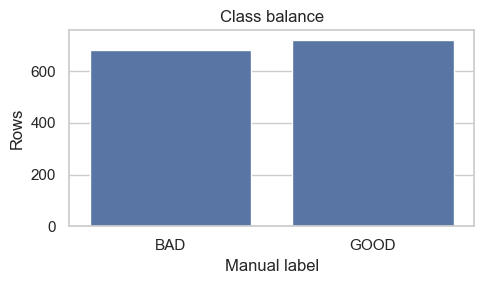

In [3]:
raw = pd.read_csv(DATA_PATH)

if LABEL_AVAILABLE_COLUMN in raw.columns:
    label_mask = raw[LABEL_AVAILABLE_COLUMN].astype(str).str.lower().isin(["true", "1", "yes"])
    data = raw.loc[label_mask].copy()
else:
    data = raw.copy()

data = data.dropna(subset=[TARGET_COLUMN]).copy()
data[TARGET_COLUMN] = data[TARGET_COLUMN].astype(int)

feature_columns = [col for col in data.columns if col.startswith(FEATURE_PREFIX)]
if len(feature_columns) < 3:
    raise ValueError(f"Need at least 3 candidate features; found {len(feature_columns)}.")

X = data[feature_columns].apply(pd.to_numeric, errors="coerce")
y = data[TARGET_COLUMN]

unexpected_labels = sorted(set(y.unique()) - {BAD_CLASS, GOOD_CLASS})
if unexpected_labels:
    raise ValueError(f"Expected binary labels 0/1 only. Unexpected labels: {unexpected_labels}")

overview = pd.DataFrame(
    {
        "item": [
            "rows in raw table",
            "labeled rows used",
            "candidate feature count",
            "BAD rows",
            "GOOD rows",
            "target column",
        ],
        "value": [
            len(raw),
            len(data),
            len(feature_columns),
            int((y == BAD_CLASS).sum()),
            int((y == GOOD_CLASS).sum()),
            TARGET_COLUMN,
        ],
    }
)

display(overview)
display(X.head())

plt.figure(figsize=(5, 3))
sns.countplot(x=y.map(LABEL_NAMES), order=["BAD", "GOOD"])
plt.title("Class balance")
plt.xlabel("Manual label")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()


## 3. Pipeline components

`TripletSelector` enforces exactly 3 original features. `AllowedArithmeticTerms` expands only those 3 features into raw/product/ratio terms using PLC-allowed arithmetic.

The pipeline is:

`feature_selection -> raw imputation -> allowed arithmetic terms -> term imputation -> variance filter -> small tree`


In [4]:
class TripletSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        if self.columns is None:
            raise ValueError("TripletSelector requires exactly 3 columns.")
        self.columns_ = list(self.columns)
        if len(self.columns_) != 3:
            raise ValueError(f"Expected exactly 3 columns, got {len(self.columns_)}: {self.columns_}")
        missing = [col for col in self.columns_ if col not in X.columns]
        if missing:
            raise ValueError(f"Columns not found in X: {missing}")
        return self

    def transform(self, X):
        check_is_fitted(self, "columns_")
        return X.loc[:, self.columns_].copy()

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "columns_")
        return np.asarray(self.columns_, dtype=object)


class AllowedArithmeticTerms(BaseEstimator, TransformerMixin):
    def __init__(self, term_family="raw_products_ratios", eps=1e-12):
        self.term_family = term_family
        self.eps = eps

    def _make_specs(self, n_features):
        if n_features != 3:
            raise ValueError(f"AllowedArithmeticTerms expects 3 input features, got {n_features}.")

        specs = [("raw", i) for i in range(n_features)]

        if "products" in self.term_family:
            specs.extend(("mul", i, j) for i, j in combinations(range(n_features), 2))

        if "ratios" in self.term_family:
            specs.extend(("div", i, j) for i in range(n_features) for j in range(n_features) if i != j)

        return specs

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.term_specs_ = self._make_specs(self.n_features_in_)
        return self

    def transform(self, X):
        check_is_fitted(self, "term_specs_")
        X = np.asarray(X, dtype=float)
        terms = []

        for spec in self.term_specs_:
            kind = spec[0]
            if kind == "raw":
                terms.append(X[:, spec[1]])
            elif kind == "mul":
                terms.append(X[:, spec[1]] * X[:, spec[2]])
            elif kind == "div":
                numerator = X[:, spec[1]]
                denominator = X[:, spec[2]]
                ratio = np.full(X.shape[0], np.nan, dtype=float)
                np.divide(
                    numerator,
                    denominator,
                    out=ratio,
                    where=np.abs(denominator) > self.eps,
                )
                terms.append(ratio)
            else:
                raise ValueError(f"Unknown term spec: {spec}")

        return np.column_stack(terms)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "term_specs_")
        if input_features is None:
            input_features = [f"x{i}" for i in range(self.n_features_in_)]
        input_features = list(input_features)

        names = []
        for spec in self.term_specs_:
            kind = spec[0]
            if kind == "raw":
                names.append(str(input_features[spec[1]]))
            elif kind == "mul":
                names.append(f"({input_features[spec[1]]} * {input_features[spec[2]]})")
            elif kind == "div":
                names.append(f"({input_features[spec[1]]} / {input_features[spec[2]]})")
        return np.asarray(names, dtype=object)


## 4. Safety-biased metrics

With `0 = BAD` and `1 = GOOD`, the dangerous industrial escape is:

`Actual BAD -> Predicted GOOD`

That is the upper-right cell of the confusion matrix when rows are `[BAD, GOOD]` and columns are `[BAD, GOOD]`.


In [5]:
def bad_recall_score(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0)


def dangerous_escape_rate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    bad_total = cm[0].sum()
    return float(cm[0, 1] / bad_total) if bad_total else 0.0


def safety_score(y_true, y_pred):
    bad_recall = recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    good_precision = precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0)
    return 0.60 * bad_recall + 0.25 * accuracy + 0.15 * good_precision


scoring = {
    "accuracy": "accuracy",
    "precision_good": make_scorer(precision_score, pos_label=GOOD_CLASS, zero_division=0),
    "recall_good": make_scorer(recall_score, pos_label=GOOD_CLASS, zero_division=0),
    "precision_bad": make_scorer(precision_score, pos_label=BAD_CLASS, zero_division=0),
    "recall_bad": make_scorer(recall_score, pos_label=BAD_CLASS, zero_division=0),
    "safety_score": make_scorer(safety_score),
}


def summarize_predictions(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "dangerous_bad_to_good_rate": dangerous_escape_rate(y_true, y_pred),
        "dangerous_bad_to_good_count": int(cm[0, 1]),
    }


## 5. Direct triplet search utilities

The search ranks candidate triplets by the best cross-validated safety score from the constrained pipeline. Each candidate uses exactly 3 original features; arithmetic expansion never introduces a fourth original feature.


In [6]:
def build_pipeline(triplet):
    return Pipeline(
        steps=[
            ("feature_selection", TripletSelector(columns=tuple(triplet))),
            ("raw_imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("allowed_terms", AllowedArithmeticTerms()),
            ("term_imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("variance_filter", "passthrough"),
            (
                "model",
                DecisionTreeClassifier(
                    random_state=RANDOM_STATE,
                    max_depth=3,
                ),
            ),
        ]
    )


def tree_param_grid(y_train):
    leaf_grid = sorted(set([1, 5, 10, max(2, int(0.02 * len(y_train)))]))
    class_weight_grid = [
        None,
        "balanced",
        {BAD_CLASS: 2.0, GOOD_CLASS: 1.0},
        {BAD_CLASS: 4.0, GOOD_CLASS: 1.0},
        {BAD_CLASS: 8.0, GOOD_CLASS: 1.0},
    ]
    return {
        "allowed_terms__term_family": TERM_FAMILIES,
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": leaf_grid,
        "model__class_weight": class_weight_grid,
    }


def screen_features_by_univariate_score(X_train, y_train, candidate_features, top_n):
    if top_n is None or top_n >= len(candidate_features):
        return list(candidate_features)

    imputed = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(
        X_train[candidate_features]
    )
    scores, _ = f_classif(imputed, y_train)
    ranked = (
        pd.Series(scores, index=candidate_features)
        .replace([np.inf, -np.inf], np.nan)
        .fillna(-np.inf)
        .sort_values(ascending=False)
    )
    return ranked.head(top_n).index.tolist()


def evaluate_triplet(triplet, X_train, y_train, inner_cv):
    triplet = tuple(triplet)
    estimator = build_pipeline(triplet)
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=tree_param_grid(y_train),
        scoring=scoring,
        refit=REFIT_METRIC,
        cv=inner_cv,
        n_jobs=INNER_GRID_N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=0,
    )

    try:
        grid.fit(X_train, y_train)
    except Exception as exc:
        return {
            "status": "failed",
            "triplet": triplet,
            "rank_score": -np.inf,
            "error": repr(exc),
            "best_params": None,
        }

    best_idx = grid.best_index_
    record = {
        "status": "ok",
        "triplet": triplet,
        "rank_score": float(grid.best_score_),
        "best_params": grid.best_params_,
        "error": None,
    }

    for metric in scoring:
        record[f"mean_test_{metric}"] = float(grid.cv_results_[f"mean_test_{metric}"][best_idx])
        record[f"std_test_{metric}"] = float(grid.cv_results_[f"std_test_{metric}"][best_idx])

    record["operator_family"] = grid.best_params_["allowed_terms__term_family"]
    record["max_depth"] = grid.best_params_["model__max_depth"]
    record["criterion"] = grid.best_params_["model__criterion"]
    record["min_samples_leaf"] = grid.best_params_["model__min_samples_leaf"]
    record["class_weight"] = grid.best_params_["model__class_weight"]
    return record


def search_triplets(
    X_train,
    y_train,
    candidate_features,
    inner_splits=INNER_SPLITS,
    max_triplets=MAX_TRIPLETS,
    screen_top_n_features=SCREEN_TOP_N_FEATURES,
    n_jobs=TRIPLET_SEARCH_N_JOBS,
):
    search_features = screen_features_by_univariate_score(
        X_train,
        y_train,
        candidate_features,
        screen_top_n_features,
    )
    triplets = list(combinations(search_features, 3))
    if max_triplets is not None:
        triplets = triplets[:max_triplets]

    inner_cv = StratifiedKFold(
        n_splits=inner_splits,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    print(
        f"Searching {len(triplets):,} triplets from {len(search_features)} candidate features "
        f"with {inner_splits}-fold inner CV."
    )

    if n_jobs == 1:
        records = [
            evaluate_triplet(triplet, X_train, y_train, inner_cv)
            for triplet in tqdm(triplets, desc="Triplets")
        ]
    else:
        records = Parallel(n_jobs=n_jobs, verbose=10)(
            delayed(evaluate_triplet)(triplet, X_train, y_train, inner_cv)
            for triplet in triplets
        )

    results = pd.DataFrame(records)
    ok = results[results["status"].eq("ok")].copy()
    failed = results[results["status"].ne("ok")].copy()

    if len(failed):
        print(f"Failed triplets: {len(failed):,}. Inspect `failed` if needed.")

    if ok.empty:
        raise RuntimeError("No valid triplet models were found.")

    ok = ok.sort_values(
        ["rank_score", "mean_test_recall_bad", "mean_test_accuracy"],
        ascending=False,
    ).reset_index(drop=True)
    ok["rank"] = np.arange(1, len(ok) + 1)
    return ok, failed


def fit_candidate_from_record(record, X_train, y_train):
    triplet = tuple(record["triplet"])
    params = dict(record["best_params"])
    estimator = build_pipeline(triplet)
    estimator.set_params(**params)
    return estimator.fit(X_train, y_train)


## 6. Optional nested CV

This is the cleanest way to estimate generalization after searching many triplets. It is off by default because it is expensive. Set `RUN_NESTED_CV = True` in the configuration cell for the publication-grade estimate.


In [7]:
nested_oof_pred = None
nested_fold_records = []

if RUN_NESTED_CV:
    outer_cv = StratifiedKFold(
        n_splits=OUTER_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    nested_oof_pred = pd.Series(index=y.index, dtype=float)

    for fold_id, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        print(f"\nOuter fold {fold_id}/{OUTER_SPLITS}")
        fold_results, fold_failed = search_triplets(
            X_train,
            y_train,
            feature_columns,
            inner_splits=INNER_SPLITS,
            max_triplets=MAX_TRIPLETS,
            screen_top_n_features=SCREEN_TOP_N_FEATURES,
            n_jobs=TRIPLET_SEARCH_N_JOBS,
        )

        best_fold_record = fold_results.iloc[0].to_dict()
        fold_model = fit_candidate_from_record(best_fold_record, X_train, y_train)
        y_pred = fold_model.predict(X_test)
        nested_oof_pred.loc[y_test.index] = y_pred

        fold_summary = summarize_predictions(y_test, y_pred)
        fold_summary.update(
            {
                "fold": fold_id,
                "triplet": best_fold_record["triplet"],
                "operator_family": best_fold_record["operator_family"],
                "inner_rank_score": best_fold_record["rank_score"],
            }
        )
        nested_fold_records.append(fold_summary)

    nested_oof_pred = nested_oof_pred.astype(int)
    nested_cv_results = pd.DataFrame(nested_fold_records)
    display(nested_cv_results)

    nested_cm = pd.DataFrame(
        confusion_matrix(y, nested_oof_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )
    display(pd.DataFrame([summarize_predictions(y, nested_oof_pred)]))
    display(nested_cm)
else:
    print("Nested CV skipped. Set RUN_NESTED_CV = True for the unbiased outer-CV estimate.")


Nested CV skipped. Set RUN_NESTED_CV = True for the unbiased outer-CV estimate.


## 7. Full-data direct search for the deployable rule

This cell performs the actual exhaustive/direct search on all labeled rows and fits the final deployable classifier. It does not estimate unbiased generalization by itself; use nested CV above for that.


In [8]:
if RUN_FINAL_SEARCH:
    final_search_results, failed_triplets = search_triplets(
        X,
        y,
        feature_columns,
        inner_splits=INNER_SPLITS,
        max_triplets=MAX_TRIPLETS,
        screen_top_n_features=SCREEN_TOP_N_FEATURES,
        n_jobs=TRIPLET_SEARCH_N_JOBS,
    )

    display(
        final_search_results[
            [
                "rank",
                "triplet",
                "operator_family",
                "rank_score",
                "mean_test_accuracy",
                "mean_test_precision_good",
                "mean_test_recall_good",
                "mean_test_precision_bad",
                "mean_test_recall_bad",
                "max_depth",
                "criterion",
                "min_samples_leaf",
                "class_weight",
            ]
        ].head(20)
    )

    best_record = final_search_results.iloc[0].to_dict()
    final_model = fit_candidate_from_record(best_record, X, y)
    print("Best deployable candidate:")
    print(f"  triplet: {best_record['triplet']}")
    print(f"  operator family: {best_record['operator_family']}")
    print(f"  safety score: {best_record['rank_score']:.4f}")
    print("  params:")
    for key, value in best_record["best_params"].items():
        print(f"    {key}: {value}")
else:
    print("Final search skipped. Set RUN_FINAL_SEARCH = True to fit the deployable model.")


Searching 5,456 triplets from 33 candidate features with 5-fold inner CV.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  5.0min
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  5.2min
[Parallel(n_jobs=-1)]: Done  41 tasks      | elapsed:  8.1min
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed: 39.3min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed: 40.8min
[Parallel(n_jobs=-1)]: Done  78 tasks      | elapsed: 42.3min
[Parallel(n_jobs=-1)]: Done  93 tasks      | elapsed: 44.9min
[Parallel(n_jobs=-1)]: Done 108 tasks      | elapsed: 46.6min
[Parallel(n_jobs=-1)]: Done 125 tasks      | elapsed: 49.3min
[Parallel(n_jobs=-1)]: Done 142 tasks      | elapsed: 52.0min
[Parallel(n_jobs=-1)]: Done 161 tasks      | elapsed: 54.8min
[Parallel(n_jobs=-1)]: Done 180 tasks      | elapsed: 56.8min
[Parallel(n_jobs=-1)]: Done 201 tasks      | elapsed: 6

,rank,triplet,operator_family,rank_score,mean_test_accuracy,mean_test_precision_good,mean_test_recall_good,mean_test_precision_bad,mean_test_recall_bad,max_depth,criterion,min_samples_leaf,class_weight
0,1,"(feature_1, feature_2, feature_5)",raw_ratios,0.939009,0.856845,0.961097,0.752126,0.787096,0.967722,3,gini,5,"{0: 4.0, 1: 1.0}"
1,2,"(feature_2, feature_5, feature_10)",raw_ratios,0.935774,0.878208,0.950811,0.804713,0.822589,0.956000,3,gini,1,"{0: 4.0, 1: 1.0}"
2,3,"(feature_2, feature_3, feature_5)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
3,4,"(feature_2, feature_5, feature_6)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
4,5,"(feature_2, feature_5, feature_7)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
5,6,"(feature_2, feature_5, feature_8)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
6,7,"(feature_2, feature_5, feature_9)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
7,8,"(feature_2, feature_5, feature_11)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
8,9,"(feature_2, feature_5, feature_12)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"
9,10,"(feature_2, feature_5, feature_13)",raw_ratios,0.932923,0.867527,0.949607,0.783927,0.807330,0.956000,3,gini,5,"{0: 4.0, 1: 1.0}"


Best deployable candidate:
  triplet: ('feature_1', 'feature_2', 'feature_5')
  operator family: raw_ratios
  safety score: 0.9390
  params:
    allowed_terms__term_family: raw_ratios
    model__class_weight: {0: 4.0, 1: 1.0}
    model__criterion: gini
    model__max_depth: 3
    model__min_samples_leaf: 5


## 8. Fixed-candidate CV diagnostics

After the final search chooses one candidate on all data, this cell evaluates that fixed candidate with cross-validation. This is useful operationally, but it is less honest than nested CV because the candidate itself was selected using all labels.


In [ ]:
if "best_record" not in globals():
    raise RuntimeError("Run the full-data direct search cell first.")

fixed_template = build_pipeline(best_record["triplet"])
fixed_template.set_params(**best_record["best_params"])

fixed_cv = StratifiedKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)
fixed_oof_pred = cross_val_predict(
    fixed_template,
    X,
    y,
    cv=fixed_cv,
    n_jobs=FIXED_CV_N_JOBS,
    method="predict",
)

fixed_metrics = pd.DataFrame([summarize_predictions(y, fixed_oof_pred)])
fixed_cm = pd.DataFrame(
    confusion_matrix(y, fixed_oof_pred, labels=[BAD_CLASS, GOOD_CLASS]),
    index=["Actual BAD (0)", "Actual GOOD (1)"],
    columns=["Pred BAD (0)", "Pred GOOD (1)"],
)

id_columns = [col for col in ["Case_ID", "Charge_ID"] if col in data.columns]
exercise5_predictions = data.loc[y.index, id_columns].copy()
exercise5_predictions.insert(0, "row_index", y.index)
exercise5_predictions["actual_label"] = y.astype(int).to_numpy()
exercise5_predictions["plc_pred_label"] = pd.Series(fixed_oof_pred, index=y.index).astype(int).to_numpy()
exercise5_predictions["actual_quality"] = exercise5_predictions["actual_label"].map(LABEL_NAMES)
exercise5_predictions["plc_pred_quality"] = exercise5_predictions["plc_pred_label"].map(LABEL_NAMES)
exercise5_predictions["cv_strategy"] = "fixed_candidate_stratified_oof"
exercise5_predictions["selected_triplet"] = str(tuple(best_record["triplet"]))
exercise5_predictions["operator_family"] = best_record["operator_family"]
exercise5_predictions.to_csv(PREDICTION_EXPORT_PATH, index=False)
print(f"Saved Exercise 5 PLC predictions to: {PREDICTION_EXPORT_PATH}")

display(fixed_metrics)
display(fixed_cm)

plt.figure(figsize=(5.5, 4))
sns.heatmap(fixed_cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Fixed-candidate CV confusion matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()


## 9. Rule extraction helpers

The final extracted tree rule uses only comparisons and logic. Arithmetic terms are listed as PLC variables so products and ratios are explicit.


In [10]:
def plc_identifier(text):
    text = str(text)
    text = text.replace("*", "_MUL_").replace("/", "_DIV_")
    text = text.replace("(", "").replace(")", "")
    text = re.sub(r"\W+", "_", text).strip("_")
    text = re.sub(r"_+", "_", text)
    if re.match(r"^\d", text):
        text = f"_{text}"
    return text


def format_threshold(value, digits=10):
    text = f"{value:.{digits}g}"
    if "e" not in text.lower() and "." in text:
        text = text.rstrip("0").rstrip(".")
    return text


def fitted_term_metadata(fitted_pipeline):
    triplet = list(fitted_pipeline.named_steps["feature_selection"].columns_)
    term_step = fitted_pipeline.named_steps["allowed_terms"]
    term_names = np.asarray(term_step.get_feature_names_out(triplet), dtype=object)
    term_specs = list(term_step.term_specs_)
    term_fills = fitted_pipeline.named_steps["term_imputer"].statistics_

    tree = fitted_pipeline.named_steps["model"]
    kept_mask = np.ones(len(term_names), dtype=bool)
    kept_original_indices = np.where(kept_mask)[0]
    used_kept_indices = sorted(set(int(i) for i in tree.tree_.feature if i >= 0))
    used_original_indices = kept_original_indices[used_kept_indices]

    rows = []
    for original_idx in used_original_indices:
        expression = term_names[original_idx]
        spec = term_specs[original_idx]
        rows.append(
            {
                "term_index": int(original_idx),
                "plc_name": plc_identifier(expression),
                "expression": expression,
                "term_kind": spec[0],
                "term_spec": spec,
                "median_fill_if_nan": float(term_fills[original_idx]),
            }
        )
    return pd.DataFrame(rows)


def original_feature_importance(fitted_pipeline):
    triplet = list(fitted_pipeline.named_steps["feature_selection"].columns_)
    term_step = fitted_pipeline.named_steps["allowed_terms"]
    term_names = np.asarray(term_step.get_feature_names_out(triplet), dtype=object)
    term_specs = list(term_step.term_specs_)
    tree = fitted_pipeline.named_steps["model"]
    importances = tree.feature_importances_

    rows = []
    for feature_idx, feature_name in enumerate(triplet):
        involved_terms = []
        total_importance = 0.0
        for tree_feature_idx, spec in enumerate(term_specs):
            if feature_idx in spec[1:]:
                importance = float(importances[tree_feature_idx])
                total_importance += importance
                if importance > 0:
                    involved_terms.append(str(term_names[tree_feature_idx]))
        rows.append(
            {
                "feature": feature_name,
                "aggregated_tree_importance": total_importance,
                "used_terms": ", ".join(involved_terms),
            }
        )
    return (
        pd.DataFrame(rows)
        .sort_values("aggregated_tree_importance", ascending=False)
        .reset_index(drop=True)
    )


def term_importance_table(fitted_pipeline):
    triplet = list(fitted_pipeline.named_steps["feature_selection"].columns_)
    term_step = fitted_pipeline.named_steps["allowed_terms"]
    term_names = np.asarray(term_step.get_feature_names_out(triplet), dtype=object)
    tree = fitted_pipeline.named_steps["model"]
    return (
        pd.DataFrame(
            {
                "plc_name": [plc_identifier(name) for name in term_names],
                "expression": term_names,
                "tree_importance": tree.feature_importances_,
            }
        )
        .query("tree_importance > 0")
        .sort_values("tree_importance", ascending=False)
        .reset_index(drop=True)
    )


def extract_leaf_rules(fitted_pipeline):
    tree_model = fitted_pipeline.named_steps["model"]
    tree = tree_model.tree_
    classes = tree_model.classes_
    term_meta = fitted_term_metadata(fitted_pipeline)
    used_aliases = term_meta["plc_name"].tolist()

    all_term_names = np.asarray(
        fitted_pipeline.named_steps["allowed_terms"].get_feature_names_out(
            fitted_pipeline.named_steps["feature_selection"].columns_
        ),
        dtype=object,
    )
    all_aliases = [plc_identifier(name) for name in all_term_names]

    rules = []

    def walk(node_id, conditions):
        left_id = tree.children_left[node_id]
        right_id = tree.children_right[node_id]

        if left_id == right_id:
            class_distribution = tree.value[node_id][0]
            weighted_class_counts = class_distribution * tree.weighted_n_node_samples[node_id]
            predicted_class = classes[int(np.argmax(class_distribution))]
            support = int(tree.n_node_samples[node_id])
            purity = (
                float(np.max(class_distribution) / np.sum(class_distribution))
                if np.sum(class_distribution)
                else np.nan
            )
            condition = " AND ".join(conditions) if conditions else "TRUE"
            rules.append(
                {
                    "condition": condition,
                    "prediction": LABEL_NAMES[int(predicted_class)],
                    "support": support,
                    "purity": purity,
                    "weighted_class_counts": {
                        LABEL_NAMES[int(cls)]: round(float(count), 3)
                        for cls, count in zip(classes, weighted_class_counts)
                    },
                }
            )
            return

        feature_idx = int(tree.feature[node_id])
        feature_alias = all_aliases[feature_idx]
        threshold = format_threshold(tree.threshold[node_id])

        left_condition = f"(({feature_alias} < {threshold}) OR ({feature_alias} == {threshold}))"
        right_condition = f"({feature_alias} > {threshold})"

        walk(left_id, conditions + [left_condition])
        walk(right_id, conditions + [right_condition])

    walk(0, [])
    return pd.DataFrame(rules), term_meta


def rules_to_if_else(rule_df):
    if len(rule_df) == 1:
        row = rule_df.iloc[0]
        return f"IF TRUE\nTHEN {row['prediction']}"

    lines = []
    for idx, row in rule_df.reset_index(drop=True).iterrows():
        is_last = idx == len(rule_df) - 1
        if is_last:
            lines.append("ELSE")
            lines.append(f"    {row['prediction']}")
        else:
            prefix = "IF" if idx == 0 else "ELSE IF"
            lines.append(f"{prefix} {row['condition']}")
            lines.append(f"THEN {row['prediction']}")
    return "\n".join(lines)


## 10. Final deliverable

This cell prints the requested output in one place:

A. selected 3 features and importance scores  
B. final PLC rule classifier  
C. CV metrics  
D. confusion matrix  
E. explanation of feature/operator selection


In [11]:
if "final_model" not in globals():
    raise RuntimeError("Run the full-data direct search cell first.")

selected_feature_importance = original_feature_importance(final_model)
selected_term_importance = term_importance_table(final_model)
rule_table, used_term_definitions = extract_leaf_rules(final_model)
plc_rules = rules_to_if_else(rule_table)

if nested_oof_pred is not None:
    evaluation_name = "Nested CV after full triplet/operator search"
    evaluation_pred = nested_oof_pred
else:
    evaluation_name = "Fixed-candidate CV diagnostics"
    evaluation_pred = fixed_oof_pred

final_metrics = pd.DataFrame([summarize_predictions(y, evaluation_pred)])
final_cm = pd.DataFrame(
    confusion_matrix(y, evaluation_pred, labels=[BAD_CLASS, GOOD_CLASS]),
    index=["Actual BAD (0)", "Actual GOOD (1)"],
    columns=["Pred BAD (0)", "Pred GOOD (1)"],
)

display(Markdown("### A) Selected 3 original features"))
display(selected_feature_importance)

display(Markdown("### Operator family and used arithmetic terms"))
operator_family = best_record["operator_family"]
allowed_operators = ["comparisons", "AND/OR"]
if "products" in operator_family:
    allowed_operators.append("*")
if "ratios" in operator_family:
    allowed_operators.append("/")

actual_operators = ["comparisons", "AND/OR"]
used_kinds = set(used_term_definitions["term_kind"])
if "mul" in used_kinds:
    actual_operators.append("*")
if "div" in used_kinds:
    actual_operators.append("/")

operator_summary = pd.DataFrame(
    [
        {
            "selected_triplet": best_record["triplet"],
            "searched_operator_family": operator_family,
            "operators_allowed_in_selected_model": ", ".join(allowed_operators),
            "operators_actually_used_in_rule": ", ".join(actual_operators),
            "tree_depth": best_record["max_depth"],
            "class_weight": best_record["class_weight"],
            "selection_score": best_record["rank_score"],
        }
    ]
)
display(operator_summary)
display(selected_term_importance)

display(Markdown("### PLC term definitions used by the tree"))
display(used_term_definitions)

display(Markdown("### B) Final PLC-compatible rule classifier"))
print(plc_rules)

display(Markdown(f"### C) Cross-validation results: {evaluation_name}"))
display(final_metrics)

display(Markdown("### D) Confusion matrix"))
display(final_cm)

display(Markdown("### E) Why these features/operators were selected"))
explanation = f'''
The selected triplet `{best_record["triplet"]}` was chosen by direct constrained search over
candidate 3-feature combinations. For each triplet, the pipeline generated only PLC-allowed
raw/product/ratio terms, tuned a shallow decision tree with StratifiedKFold CV, and ranked
candidates using `{REFIT_METRIC}`. This score emphasizes BAD-class recall, so the search is
biased against the dangerous error where an actual BAD batch is released as GOOD.

The reported feature importances aggregate the final tree's split importance across all
selected raw/product/ratio terms involving each original feature. The term table shows which
specific arithmetic expressions the final rule actually used.
'''
display(Markdown(explanation))


### A) Selected 3 original features

,feature,aggregated_tree_importance,used_terms
0,feature_5,0.886168,"feature_5, (feature_1 / feature_5), (feature_5..."
1,feature_2,0.118967,"feature_2, (feature_2 / feature_1), (feature_5..."
2,feature_1,0.083227,"(feature_1 / feature_5), (feature_2 / feature_1)"


### Operator family and used arithmetic terms

,selected_triplet,searched_operator_family,operators_allowed_in_selected_model,operators_actually_used_in_rule,tree_depth,class_weight,selection_score
0,"(feature_1, feature_2, feature_5)",raw_ratios,"comparisons, AND/OR, /","comparisons, AND/OR, /",3,"{0: 4.0, 1: 1.0}",0.939009


,plc_name,expression,tree_importance
0,feature_5,feature_5,0.875448
1,feature_2_DIV_feature_1,(feature_2 / feature_1),0.077642
2,feature_2,feature_2,0.036190
3,feature_1_DIV_feature_5,(feature_1 / feature_5),0.005585
4,feature_5_DIV_feature_2,(feature_5 / feature_2),0.005135


### PLC term definitions used by the tree

... (5 outputs left out)

### D) Confusion matrix

,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),660,22
Actual GOOD (1),179,543


### E) Why these features/operators were selected


The selected triplet `('feature_1', 'feature_2', 'feature_5')` was chosen by direct constrained search over
candidate 3-feature combinations. For each triplet, the pipeline generated only PLC-allowed
raw/product/ratio terms, tuned a shallow decision tree with StratifiedKFold CV, and ranked
candidates using `safety_score`. This score emphasizes BAD-class recall, so the search is
biased against the dangerous error where an actual BAD batch is released as GOOD.

The reported feature importances aggregate the final tree's split importance across all
selected raw/product/ratio terms involving each original feature. The term table shows which
specific arithmetic expressions the final rule actually used.


## 11. PLC deployment notes

- Implement the three selected original features exactly as engineered in the training table.
- Apply the same median fills shown by the fitted imputers if your PLC/MES can receive missing values.
- Ratio terms need a denominator guard. If the denominator is zero, use the listed `median_fill_if_nan` for that PLC term.
- Monitor `Actual BAD -> Predicted GOOD` after deployment; this is the safety-critical miss.
